# DocumentAgent — Extraction Demo

This notebook demonstrates DocumentAgent's document extraction pipeline using the **Landing AI AIDE API**.

Upload any scanned or photographed document to see structured, layout-aware text extraction. Tesseract is included as a traditional OCR baseline to illustrate the difference.

In [1]:
!pip install landingai-ade pytesseract pillow pandas python-dotenv matplotlib

In [2]:
try:
    import re
    import os
    from pathlib import Path
    import pandas as pd
    import pytesseract

    from PIL import Image
    from dotenv import load_dotenv
    from landingai_ade import LandingAIADE
    print("All modules imported successfully.")
except ImportError as e:
    print(f"Error importing modules: {e}")
    print("Please ensure all required libraries are installed.")

All modules imported successfully.


In [3]:
load_dotenv()

API_KEY = os.getenv("VISION_AGENT_API_KEY")
if API_KEY:
    print("API key loaded successfully.")
if not API_KEY:
    raise ValueError("VISION_AGENT_API_KEY not found in .env")

API key loaded successfully.


In [4]:
SAMPLE_PATH = Path("../samples/sample_image.jpg")

if not SAMPLE_PATH.exists():
    raise FileNotFoundError(f"Sample document not found: {SAMPLE_PATH}")
else:
    print(f"Loaded: {SAMPLE_PATH.name}")

Loaded: sample_image.jpg


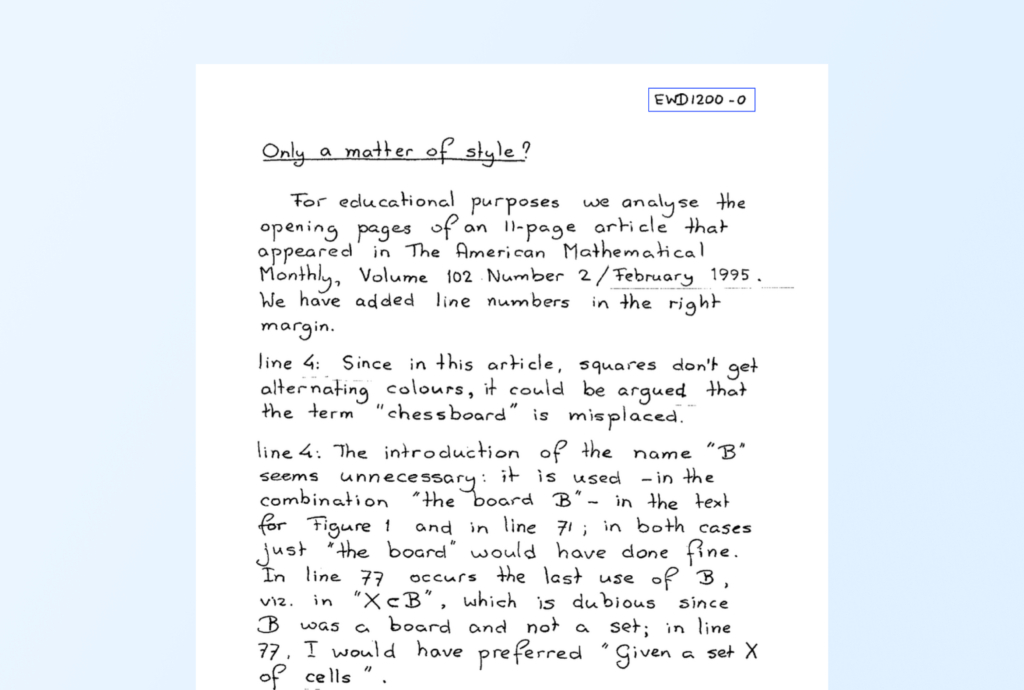

In [5]:
image = Image.open(SAMPLE_PATH)

image

In [6]:
client = LandingAIADE(apikey=API_KEY)

response = client.parse(
    document=SAMPLE_PATH,
    model="dpt-2-mini"
)

print("Extraction completed")

Extraction completed


In [7]:
metadata = {
    "filename": response.metadata.filename,
    "pages": response.metadata.page_count,
    "credits_used": response.metadata.credit_usage,
    "duration_ms": response.metadata.duration_ms,
}

metadata

{'filename': 'sample_image.jpg',
 'pages': 1,
 'credits_used': 1.5,
 'duration_ms': 2375}

# Landing AI AIDE Extraction

In [8]:
aide_text = re.sub(r'<a[^>]+></a>\s*\n?', '', response.markdown).strip()
print(aide_text)

EWD1200 - 0

__Only a matter of style?__

For educational purposes we analyse the
opening pages of an 11-page article that
appeared in The American Mathematical
Monthly, Volume 102 Number 2/February 1995.
We have added line numbers in the right
margin.

line 4: Since in this article, squares don't get
alternating colours, it could be argued that
the term "chessboard" is misplaced.

line 4: The introduction of the name "B"
seems unnecessary: it is used -in the
combination "the board B" - in the text
for Figure 1 and in line 71; in both cases
just "the board" would have done fine.
In line 77 occurs the last use of B,
viz. in "X $\subset$ B", which is dubious since
B was a board and not a set; in line
77, I would have preferred "Given a set X
of cells".


In [9]:
print(f"AIDE extracted {len(response.chunks)} structured chunk(s) | "
      f"{response.metadata.credit_usage} credits | "
      f"{response.metadata.duration_ms}ms")

AIDE extracted 4 structured chunk(s) | 1.5 credits | 2375ms


# Tesseract OCR — Legacy Baseline

In [10]:
tesseract_text = pytesseract.image_to_string(image)
tesseract_data = pytesseract.image_to_data(image, output_type=pytesseract.Output.DICT)

In [11]:
print(tesseract_text)

EWD1200 -o
Only a mother of style 2

For educational purposes we analyse the
openin es of an Il-page article that
bs tarde Ta Fae Mathematical
Monthly, Volume {02 Number 2/ February 1995.
We have added line numbers in the right
margin.
line 4: Since in this article, squares don't oe}
alternating colours, it could be argued that
the term “chessboard” is misplaced.

line 4: The introduction of the name “B’

seems Unnecessary: it is used -in the
combination “the board B"~ in the text
Figure 1 and in line 7; in both cases

et “the board” would have done Rne.
in line 77 occurs the last use of B,
wiz. in “XoB", which is dubious since
B was a board and nob a set; in line
77, T would hove preferred “Given a set X

of cells ”



In [12]:
tesseract_rows = [
    {"text": tesseract_data["text"][i], "confidence": round(tesseract_data["conf"][i] / 100, 3)}
    for i in range(len(tesseract_data["text"]))
    if tesseract_data["conf"][i] > 0 and tesseract_data["text"][i].strip()
]

tesseract_df = pd.DataFrame(tesseract_rows)

tesseract_df.head()

,text,confidence
0,EWD1200,0.64
1,-o,0.34
2,Only,0.33
3,a,0.33
4,mother,0.33


In [13]:
summary = pd.DataFrame({
    "": ["DocumentAgent (Landing AI AIDE)", "Tesseract (Legacy OCR)"],
    "Structured output": ["Yes — paragraph-level chunks", "No — raw text only"],
    "Layout preserved": ["Yes", "Partial"],
    "Requires API key": ["Yes", "No"],
    "Runs offline": ["No", "Yes"],
})

summary.set_index("", inplace=True)
summary

,Structured output,Layout preserved,Requires API key,Runs offline
,,,,
DocumentAgent (Landing AI AIDE),Yes — paragraph-level chunks,Yes,Yes,No
Tesseract (Legacy OCR),No — raw text only,Partial,No,Yes


In [14]:
output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)

base_name = SAMPLE_PATH.stem

with open(output_dir / f"{base_name}_landingai_output.md", "w", encoding="utf-8") as f:
    f.write(response.markdown)

with open(output_dir / f"{base_name}_tesseract_output.txt", "w", encoding="utf-8") as f:
    f.write(tesseract_text)

print("Outputs saved to outputs/")

Outputs saved to outputs/


## Conclusion

DocumentAgent uses Landing AI AIDE to extract structured, layout-aware text from documents — preserving paragraphs, formatting, and reading order.

Tesseract, shown here as a legacy OCR baseline, produces raw unstructured text and is more error-prone on complex layouts. It is included for reference only.